# 第14章 傅里叶变换（跟随代码）

> 《OpenCV轻松入门：面向Python》第 14 章的跟随代码，内容未做改动。
> 运行前请确认工作目录为本文件夹（picture*.jpg 等素材都在这里）。

# 第十四章 傅里叶变换

## numpy实现傅里叶变换

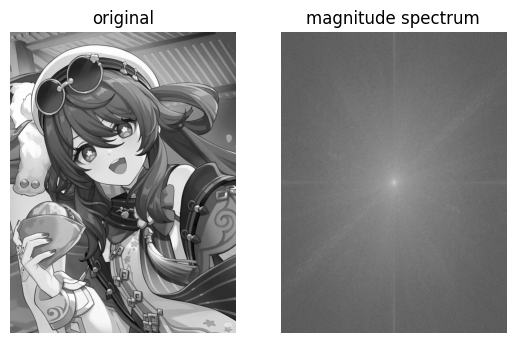

In [259]:
img=cv2.imread("picture2.png",cv2.IMREAD_GRAYSCALE)

f=np.fft.fft2(img)

fshift=np.fft.fftshift(f)

magnitude_spectrum=20*np.log(np.abs(fshift))

plt.subplot(121),plt.imshow(img, cmap='gray')
plt.title("original")
plt.axis('off')
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("magnitude spectrum")
plt.axis('off')
plt.show()

### 实现逆傅里叶变换


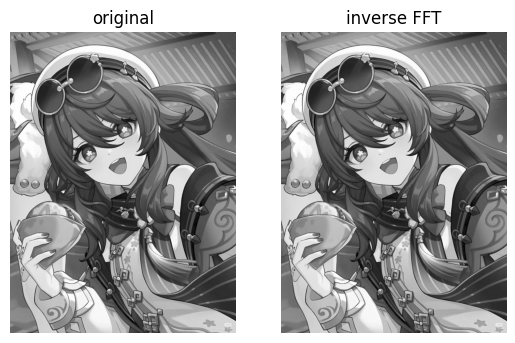

In [260]:
def cv_show(name,img):
    cv2.imshow(name,img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


import cv2
import numpy as np
import matplotlib.pyplot as plt

img=cv2.imread("picture2.png",cv2.IMREAD_GRAYSCALE)

f=np.fft.fft2(img)
fshift=np.fft.fftshift(f)

ishift=np.fft.ifftshift(fshift)

iimg=np.fft.ifft2(ishift)

iimg=np.abs(iimg)

plt.subplot(121),plt.imshow(img,cmap='gray')
plt.title("original"),plt.axis("off")

plt.subplot(122),plt.imshow(iimg,cmap='gray')
plt.title("inverse FFT"),plt.axis("off")

plt.show()

### 高通滤波示例

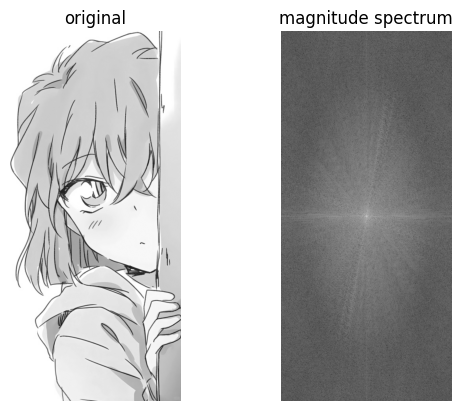

C:\Users\17272\AppData\Local\Temp\ipykernel_43968\2780109876.py:23: RuntimeWarning: divide by zero encountered in log
  magnitude_spectrum=20*np.log(np.abs(fshift))


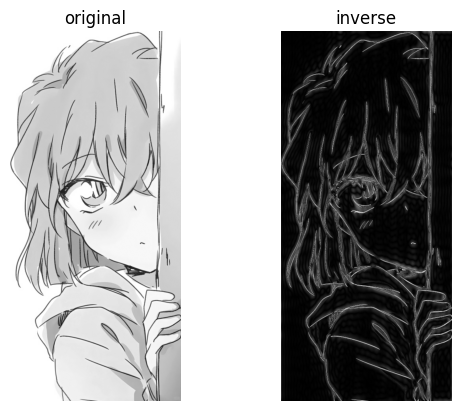

In [261]:
img=cv2.imread("picture8.jpg",cv2.IMREAD_GRAYSCALE)

f=np.fft.fft2(img)

fshift=np.fft.fftshift(f)

magnitude_spectrum=20*np.log(np.abs(fshift))

plt.subplot(121),plt.imshow(img, cmap='gray')
plt.title("original")
plt.axis('off')
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("magnitude spectrum")
plt.axis('off')
plt.show()

rows,cols=img.shape

crow,ccol=int(rows/2),int(cols/2)

fshift[crow-30:crow+30, ccol-30:ccol+30]=0

magnitude_spectrum=20*np.log(np.abs(fshift))

ishift=np.fft.ifftshift(fshift)
iimg=np.fft.ifft2(ishift)

iimg=np.abs(iimg)

plt.subplot(121),plt.imshow(img, cmap='gray')
plt.title("original")
plt.axis('off')
plt.subplot(122),plt.imshow(iimg, cmap='gray')
plt.title("inverse")
plt.axis('off')
plt.show()

## 用opencv实现傅里叶变换

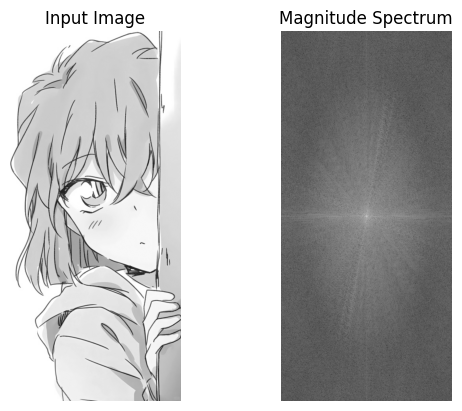

In [262]:
img=cv2.imread('picture8.jpg',cv2.IMREAD_GRAYSCALE)

dft=cv2.dft(np.float32(img),flags=cv2.DFT_COMPLEX_OUTPUT)

dftshift=np.fft.fftshift(dft)

result=20*np.log(cv2.magnitude(dftshift[:, :, 0], dftshift[:, :, 1]))

plt.subplot(121),plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.axis('off')

plt.subplot(122),plt.imshow(result, cmap='gray')
plt.title('Magnitude Spectrum'), plt.axis('off')

plt.show()

### 实现逆傅里叶变换

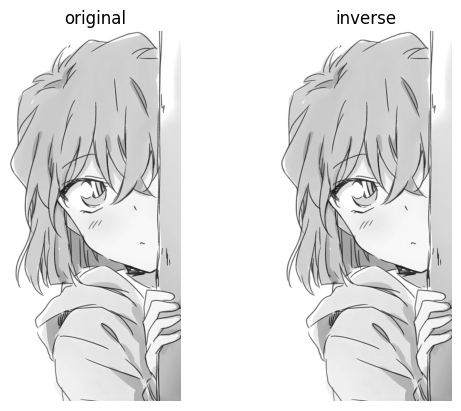

In [263]:
img=cv2.imread("picture8.jpg",cv2.IMREAD_GRAYSCALE)
dft=cv2.dft(np.float32(img),flags=cv2.DFT_COMPLEX_OUTPUT)
dftshift=np.fft.fftshift(dft)


ishift=np.fft.ifftshift(dftshift)
iimg=cv2.idft(ishift)
iimg=cv2.magnitude(iimg[:,:,0],iimg[:,:,1])
plt.subplot(121),plt.imshow(img,cmap='gray')
plt.title("original"),plt.axis("off")

plt.subplot(122),plt.imshow(iimg,cmap='gray')
plt.title("inverse"),plt.axis("off")

plt.show()



### 低通滤波示例


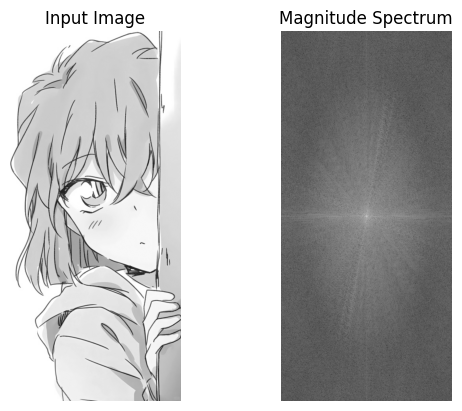

C:\Users\17272\AppData\Local\Temp\ipykernel_43968\1800006581.py:27: RuntimeWarning: divide by zero encountered in log
  magnitude_spectrum1=20*np.log(cv2.magnitude(fshift[:, :, 0], fshift[:, :, 1]))


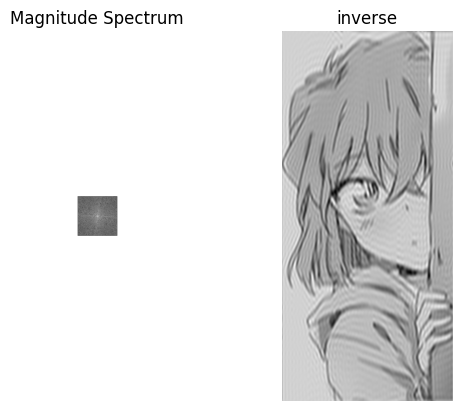

In [264]:
img=cv2.imread('picture8.jpg',cv2.IMREAD_GRAYSCALE)

dft=cv2.dft(np.float32(img),flags=cv2.DFT_COMPLEX_OUTPUT)

dftshift=np.fft.fftshift(dft)

result=20*np.log(cv2.magnitude(dftshift[:, :, 0], dftshift[:, :, 1]))

plt.subplot(121),plt.imshow(img, cmap='gray')
plt.title('Input Image'), plt.axis('off')

plt.subplot(122),plt.imshow(result, cmap='gray')
plt.title('Magnitude Spectrum'), plt.axis('off')

plt.show()


rows,cols=img.shape

mask=np.zeros((rows,cols,2),np.uint8)

crows,ccols=rows//2,cols//2

mask[crows-50:crows+50, ccols-50:ccols+50]=1

fshift=dftshift*mask
magnitude_spectrum1=20*np.log(cv2.magnitude(fshift[:, :, 0], fshift[:, :, 1]))
plt.subplot(121),plt.imshow(magnitude_spectrum1, cmap='gray')
plt.title('Magnitude Spectrum'), plt.axis('off')
ishift=np.fft.ifftshift(fshift)
iimg=cv2.idft(ishift)
iimg=cv2.magnitude(iimg[:,:,0],iimg[:,:,1])
plt.subplot(122),plt.imshow(iimg,cmap="gray"),plt.axis("off")
plt.title("inverse")
plt.show()